# Week 3 · Notebook 2 - MDPs and Q-learning

Bandits had one state. Real problems have **states that change because of our actions**. That is a **Markov Decision Process (MDP)**: states $S$, actions $A$, rewards $R$, transitions, and a discount $\gamma$.

Our toy world: get from **S** to the exam hall **G** (+10) without touching a phone **X** (−5). Each step costs −0.1.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # so we can import the remind package
import random
import matplotlib.pyplot as plt
from remind.rl.gridworld import GridWorld, LAYOUT
from remind.rl.qlearning import QLearningAgent, train
print('\n'.join(LAYOUT))

S...
.#.X
....
X..G


## 1. The agent-environment loop
```
state = env.reset()
while not done:
    action = agent.act(state)
    next_state, reward, done, info = env.step(action)
    agent.update(state, action, reward, next_state, done)
    state = next_state
```
Every RL program you will ever write has this loop - including the Re-Mind scheduler next week.

In [2]:
env = GridWorld()
s = env.reset()
for a in [3, 3, 1, 1]:          # right, right, down, down
    s, r, done, _ = env.step(a)
    print(f'state {s:2d}  reward {r:+.1f}  done {done}')

state  1  reward -0.1  done False
state  2  reward -0.1  done False
state  6  reward -0.1  done False
state 10  reward -0.1  done False


## 2. Return, discount, and Q-values
Return $G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$  ($\gamma<1$: sooner rewards matter more).

$Q(s,a)$ = expected return if we take $a$ in $s$ and act well afterwards. If we knew $Q$, acting is easy: $\pi(s)=\arg\max_a Q(s,a)$.

## 3. The Q-learning update
$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\,\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{target}} - Q(s,a)\Big]$$
Same shape as the bandit running mean - but the target now *looks one step ahead*. Read `remind/rl/qlearning.py`: it is ~40 lines.

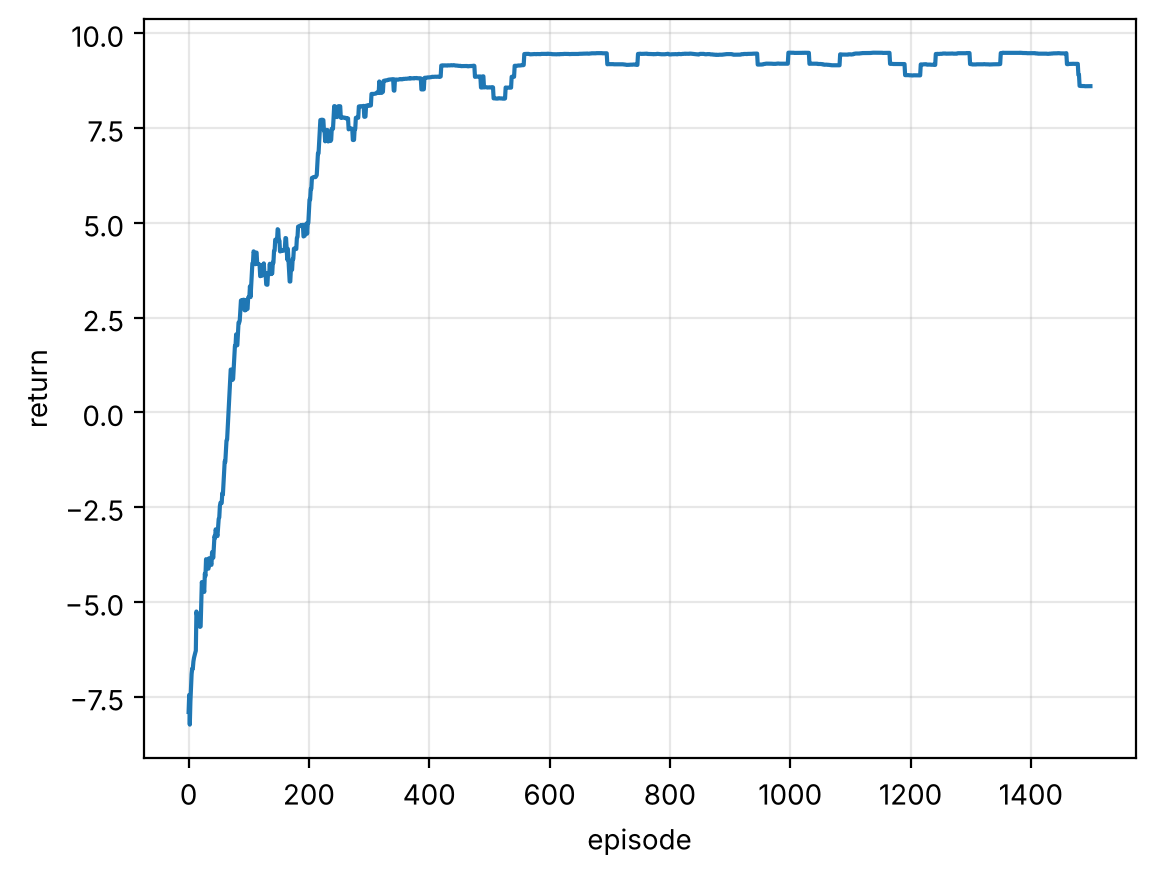

>>v<
^#vX
>>vv
X>>G


In [3]:
agent = QLearningAgent(env.n_states, env.n_actions, alpha=0.1, gamma=0.95, epsilon_decay=0.995, seed=0)
returns = train(env, agent, episodes=1500)
smooth = [sum(returns[max(0,i-50):i+1]) / len(returns[max(0,i-50):i+1]) for i in range(len(returns))]
plt.plot(smooth); plt.xlabel('episode'); plt.ylabel('return'); plt.grid(alpha=.3); plt.show()
print(env.render_policy(agent.q))

The arrows are the **greedy policy**. Notice it avoids both phones and takes a shortest path.

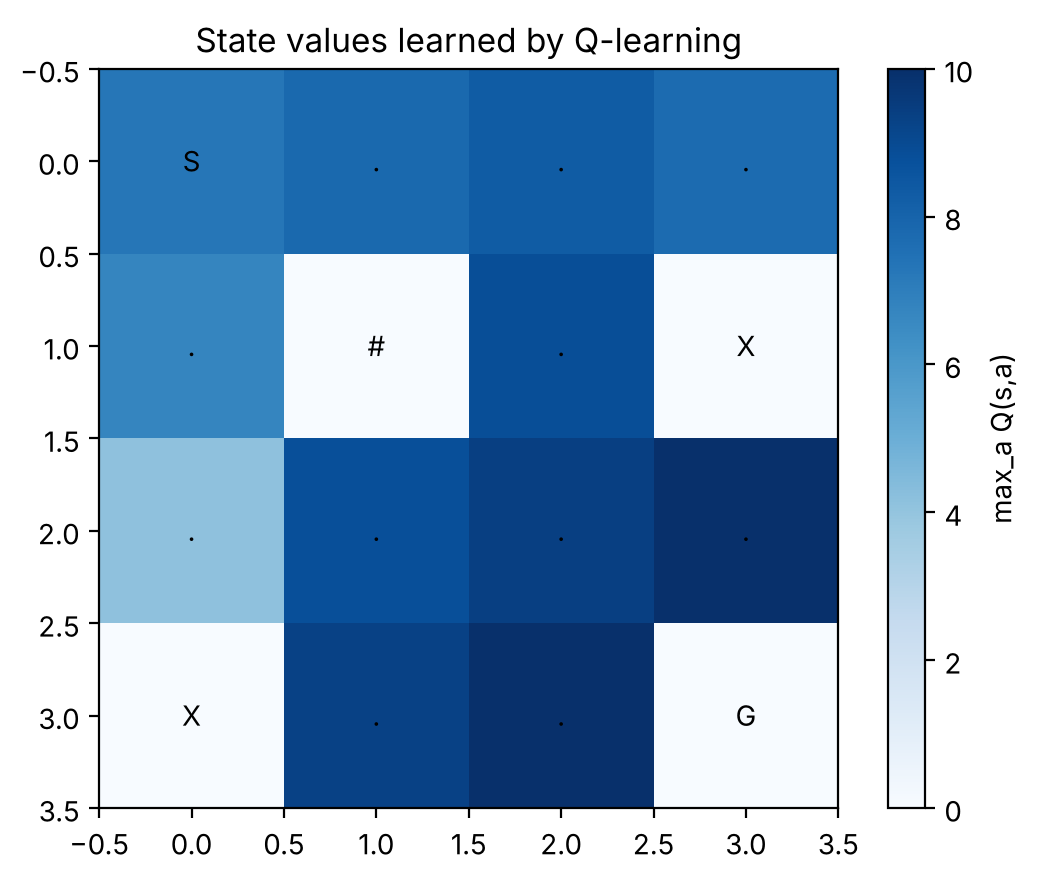

In [4]:
import numpy as np
V = np.array([max(row) for row in agent.q]).reshape(4, 4)
plt.imshow(V, cmap='Blues'); plt.colorbar(label='max_a Q(s,a)')
for r in range(4):
    for c in range(4):
        plt.text(c, r, LAYOUT[r][c], ha='center', va='center')
plt.title('State values learned by Q-learning'); plt.show()

## ✍️ Exercises
1. Set `gamma=0.5` and `gamma=0.99`. How does the value map change? Explain in your words.
2. Set the step cost to 0. Does the agent still take the shortest path? Why not?
3. Make the floor *slippery*: with prob 0.2 the agent moves in a random direction (edit a copy of `GridWorld.step`). What does the new policy do near the phones?
4. Implement **SARSA** (target uses the action actually taken next, not the max). Compare the paths near the phones.